# Apriori Model Evaluation - Recommendation Quality & Coverage

**Goal:** Evaluate the production Apriori association rule model trained on Retailrocket session baskets (`addtocart` + `transaction`) using intrinsic rule metrics, catalog coverage analysis, and offline top-K ranking evaluation (`Hit Rate@K`, `Precision@K`, `Recall@K`).

**Key Questions Addressed:**
1. What are the statistical distributions of `support`, `confidence`, and `lift` across the production rules?
2. How much of the active product catalog and multi-item shopping sessions are covered by the mined rules?
3. How does the Apriori model perform on held-out test baskets compared to a Popularity Baseline at $K \in \{1, 3, 5, 10\}$?
4. How does tuning the `min_confidence` threshold trade off recommendation precision against basket coverage?

## 1. Imports and Setup

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# Add ml-service root to sys.path to reuse pipeline and evaluation modules
ml_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path('ml-service').resolve()
sys.path.insert(0, str(ml_root))

from src.config import MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT
from src.pipeline import load_baskets, mine_association_rules
from src.evaluate import (
    split_baskets,
    build_rule_lookup,
    get_popular_items,
    compute_rule_statistics,
    evaluate_recommendations_at_k,
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['figure.dpi'] = 100

## 2. Production Rule Quality & Distribution Analysis

First, we load the multi-item session baskets (`addtocart` and `transaction` events grouped by visitor and calendar day) and mine the pairwise 1-to-1 association rules using our production hyperparameters (`min_support = 0.0005`, `min_confidence = 0.10`, `min_lift = 1.20`).

In [2]:
# Load multi-item session baskets and mine pairwise rules
baskets = load_baskets()
df_rules = mine_association_rules(
    baskets,
    min_support=MIN_SUPPORT,
    min_confidence=MIN_CONFIDENCE,
    min_lift=MIN_LIFT,
)

df_rules[['support', 'confidence', 'lift']].describe().round(4)

[Pipeline] Processed Parquet not found. Falling back to raw CSV: C:\Users\Błażej\Documents\GitHub\retailrocket-recommender-system\data\raw\events.csv
[Pipeline] Total baskets: 43,265 | Multi-item baskets (>= 2 items): 8,111
[Pipeline] Encoded boolean matrix shape: (8111, 16315)
[Pipeline] Frequent itemsets discovered: 1,110
[Pipeline] Final pairwise recommendation rules: 172


,support,confidence,lift
count,172.0000,172.0000,172.0000
mean,0.0010,0.5344,368.0552
std,0.0007,0.2711,410.5270
min,0.0006,0.1163,18.2516
25%,0.0006,0.2958,77.8834
50%,0.0007,0.4752,167.9361
75%,0.0009,0.7778,477.1176
max,0.0049,1.0000,1622.2000


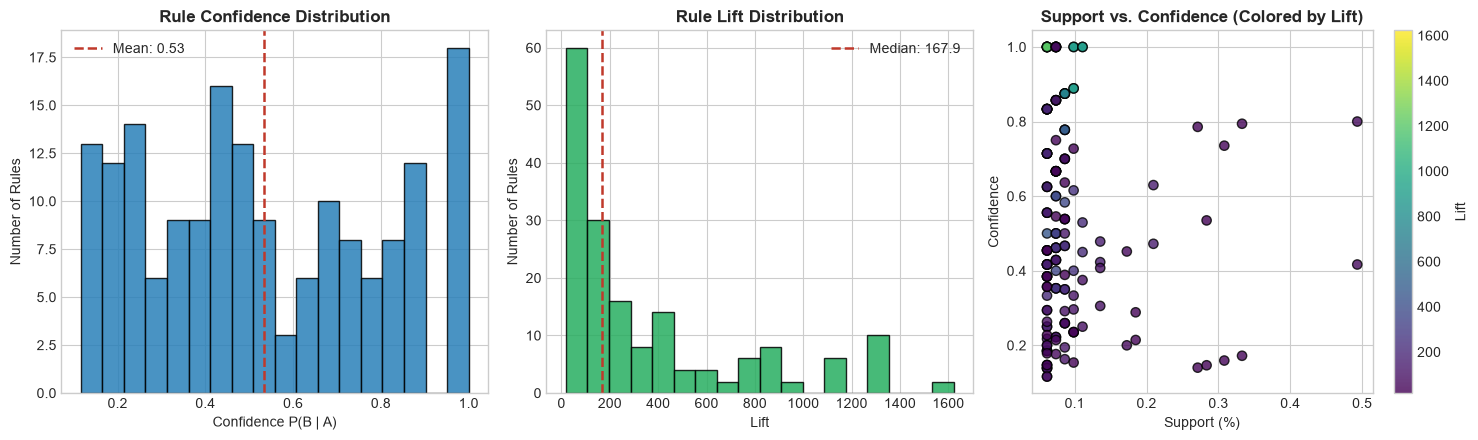

In [3]:
# Visualize distributions of Support, Confidence, and Lift
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Confidence distribution
axes[0].hist(df_rules['confidence'], bins=18, color='#2980b9', edgecolor='black', alpha=0.85)
axes[0].axvline(df_rules['confidence'].mean(), color='#c0392b', linestyle='--', linewidth=1.8, label=f"Mean: {df_rules['confidence'].mean():.2f}")
axes[0].set_title('Rule Confidence Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Confidence P(B | A)')
axes[0].set_ylabel('Number of Rules')
axes[0].legend()

# 2. Lift distribution
axes[1].hist(df_rules['lift'], bins=18, color='#27ae60', edgecolor='black', alpha=0.85)
axes[1].axvline(df_rules['lift'].median(), color='#c0392b', linestyle='--', linewidth=1.8, label=f"Median: {df_rules['lift'].median():.1f}")
axes[1].set_title('Rule Lift Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lift')
axes[1].set_ylabel('Number of Rules')
axes[1].legend()

# 3. Support vs Confidence colored by Lift
scatter = axes[2].scatter(
    df_rules['support'] * 100,
    df_rules['confidence'],
    c=df_rules['lift'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='k',
    s=45,
)
cbar = plt.colorbar(scatter, ax=axes[2])
cbar.set_label('Lift')
axes[2].set_title('Support vs. Confidence (Colored by Lift)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Support (%)')
axes[2].set_ylabel('Confidence')

plt.tight_layout()
plt.show()

## 3. Catalog & Basket Coverage Analysis

In e-commerce datasets with a long tail of rarely viewed products, only items with recurrent co-occurrences pass the support filter. Here we check how many unique items participate in rules and what share of multi-item shopping sessions contain at least one trigger product (`if_item_id`).

In [4]:
stats = compute_rule_statistics(df_rules, baskets)

print(f"Total pairwise rules:                {stats['rules_count']:,}")
print(f"Unique trigger items (if_item_id):   {stats['unique_antecedents']:,}")
print(f"Unique target items (then_item_id):  {stats['unique_consequents']:,}")
print(f"Total unique items in rules:         {stats['unique_rule_items']:,} / {stats['catalog_items']:,} ({stats['item_coverage_pct']}%)")
print(f"Multi-item basket coverage:          {stats['basket_coverage_pct']}% of sessions contain a trigger item")
print(f"Average recommendations per item:    {stats['avg_rules_per_item']} rules")

Total pairwise rules:                172
Unique trigger items (if_item_id):   100
Unique target items (then_item_id):  87
Total unique items in rules:         101 / 16,315 (0.62%)
Multi-item basket coverage:          11.96% of sessions contain a trigger item
Average recommendations per item:    1.72 rules


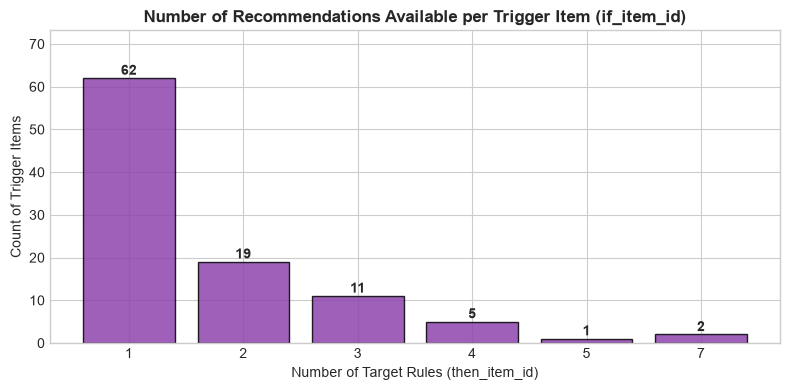

In [5]:
# Distribution of recommendation count per trigger item (if_item_id)
rules_per_trigger = df_rules.groupby('if_item_id')['then_item_id'].count().value_counts().sort_index()

plt.figure(figsize=(8, 4))
bars = plt.bar(rules_per_trigger.index.astype(str), rules_per_trigger.values, color='#8e44ad', edgecolor='black', alpha=0.85)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.8, f'{int(height)}', ha='center', fontsize=10, fontweight='bold')

plt.title('Number of Recommendations Available per Trigger Item (if_item_id)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Target Rules (then_item_id)')
plt.ylabel('Count of Trigger Items')
plt.ylim(0, max(rules_per_trigger.values) * 1.18)
plt.tight_layout()
plt.show()

## 4. Train / Test Split & Offline Ranking Protocol

To evaluate how accurately the rules predict co-occurring items in unseen shopping sessions, we split the `8,111` multi-item baskets into an **80% training set** (`6,488` baskets) and a **20% held-out test set** (`1,623` baskets).

For every test basket $B$ and each trigger item $x \in B$, the ground-truth set of co-interacted items is $G = B \setminus \{x\}$. Given the top-$K$ recommended list $R_K(x)$, we measure:
- **Hit Rate@K:** Percentage of test queries where at least one recommended item in $R_K(x)$ belongs to $G$.
- **Precision@K:** Fraction of recommended items in $R_K(x)$ that belong to $G$: $\frac{|R_K(x) \cap G|}{K}$.
- **Recall@K:** Fraction of ground-truth basket items recovered in $R_K(x)$: $\frac{|R_K(x) \cap G|}{|G|}$.

We compare three strategies:
1. **Apriori (Covered Items):** Evaluates test queries where `if_item_id` has mined rules in the lookup table.
2. **Apriori + Popularity (Hybrid):** Uses Apriori rules first and fills remaining slots up to $K$ with the most popular training items across all test queries.
3. **Popularity Baseline:** Recommends the top-$K$ most frequent items from the training set across all test queries.

In [6]:
# Split multi-item baskets into 80% train and 20% test
train_baskets, test_baskets = split_baskets(baskets, test_ratio=0.20, seed=42)
print(f'Train baskets: {len(train_baskets):,} | Test baskets: {len(test_baskets):,}')

# Mine Apriori rules strictly on training baskets
train_rules = mine_association_rules(
    train_baskets,
    min_support=MIN_SUPPORT,
    min_confidence=MIN_CONFIDENCE,
    min_lift=MIN_LIFT,
)
rule_lookup = build_rule_lookup(train_rules)
popular_items = get_popular_items(train_baskets, top_n=50)

# Evaluate Hit Rate@K, Precision@K, and Recall@K for K in [1, 3, 5, 10]
df_eval = evaluate_recommendations_at_k(
    test_baskets=test_baskets,
    rule_lookup=rule_lookup,
    popular_items=popular_items,
    k_values=[1, 3, 5, 10],
)
df_eval

Train baskets: 6,488 | Test baskets: 1,623
[Pipeline] Encoded boolean matrix shape: (6488, 14106)
[Pipeline] Frequent itemsets discovered: 1,329
[Pipeline] Final pairwise recommendation rules: 303


,model,k,queries_evaluated,hit_rate_pct,precision_pct,recall_pct
0,Apriori (Covered Items),1,346,30.35,30.35,11.81
1,Apriori + Popularity (Hybrid),1,6257,2.53,2.53,0.85
2,Popularity Baseline,1,6257,1.31,1.31,0.42
3,Apriori (Covered Items),3,346,41.04,15.80,18.16
4,Apriori + Popularity (Hybrid),3,6257,8.39,2.95,1.85
5,Popularity Baseline,3,6257,6.94,2.34,1.20
6,Apriori (Covered Items),5,346,45.95,10.64,21.52
7,Apriori + Popularity (Hybrid),5,6257,10.07,2.14,2.39
8,Popularity Baseline,5,6257,8.60,1.76,1.71
9,Apriori (Covered Items),10,346,46.53,5.52,22.30


## 5. Visualizing Ranking Performance (@K)

The charts below compare the ranking metrics across $K \in \{1, 3, 5, 10\}$. When a shopper views or adds an item covered by Apriori rules, the recommendation accuracy is an order of magnitude higher than recommending globally popular products.

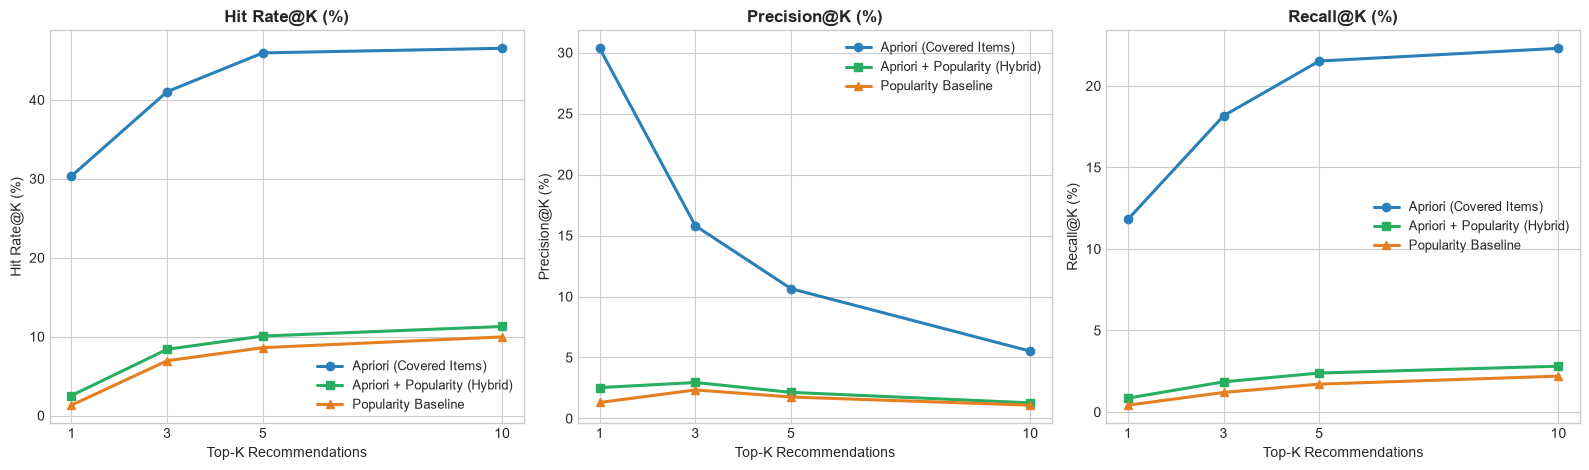

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
models = ['Apriori (Covered Items)', 'Apriori + Popularity (Hybrid)', 'Popularity Baseline']
colors = {'Apriori (Covered Items)': '#2980b9', 'Apriori + Popularity (Hybrid)': '#27ae60', 'Popularity Baseline': '#e67e22'}
markers = {'Apriori (Covered Items)': 'o', 'Apriori + Popularity (Hybrid)': 's', 'Popularity Baseline': '^'}

metrics = [
    ('hit_rate_pct', 'Hit Rate@K (%)'),
    ('precision_pct', 'Precision@K (%)'),
    ('recall_pct', 'Recall@K (%)'),
]

for ax, (col, title) in zip(axes, metrics):
    for m in models:
        sub = df_eval[df_eval['model'] == m]
        ax.plot(sub['k'], sub[col], marker=markers[m], color=colors[m], linewidth=2.2, label=m)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Top-K Recommendations')
    ax.set_ylabel(title)
    ax.set_xticks([1, 3, 5, 10])
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 6. Threshold Trade-off: Confidence vs. Coverage

Increasing `min_confidence` makes rules stricter, which raises precision on covered items but reduces the number of items that receive recommendations. We evaluate this trade-off at $K = 5$.

In [8]:
confidence_grid = [0.05, 0.10, 0.20, 0.35, 0.50, 0.70]
tradeoff_rows = []

for conf in confidence_grid:
    filtered_train = train_rules[train_rules['confidence'] >= conf]
    lookup_c = build_rule_lookup(filtered_train)
    eval_c = evaluate_recommendations_at_k(test_baskets, lookup_c, popular_items, k_values=[5])
    cov_row = eval_c[eval_c['model'] == 'Apriori (Covered Items)'].iloc[0]
    tradeoff_rows.append({
        'min_confidence': conf,
        'train_rules': len(filtered_train),
        'covered_test_queries': int(cov_row['queries_evaluated']),
        'hit_rate_at_5_pct': cov_row['hit_rate_pct'],
        'precision_at_5_pct': cov_row['precision_pct'],
    })

df_tradeoff = pd.DataFrame(tradeoff_rows)
df_tradeoff

,min_confidence,train_rules,covered_test_queries,hit_rate_at_5_pct,precision_at_5_pct
0,0.05,303,346,45.95,10.64
1,0.10,303,346,45.95,10.64
2,0.20,285,320,44.38,10.50
3,0.35,251,242,48.35,10.74
4,0.50,221,176,48.86,11.02
5,0.70,148,74,58.11,14.59


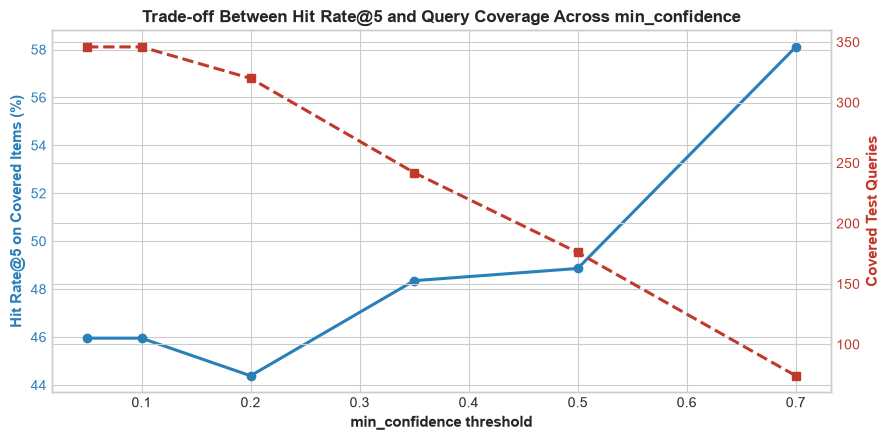

In [9]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color_hr = '#2980b9'
ax1.set_xlabel('min_confidence threshold', fontsize=11, fontweight='bold')
ax1.set_ylabel('Hit Rate@5 on Covered Items (%)', color=color_hr, fontsize=11, fontweight='bold')
ax1.plot(df_tradeoff['min_confidence'], df_tradeoff['hit_rate_at_5_pct'], marker='o', color=color_hr, linewidth=2.2)
ax1.tick_params(axis='y', labelcolor=color_hr)

ax2 = ax1.twinx()
color_cov = '#c0392b'
ax2.set_ylabel('Covered Test Queries', color=color_cov, fontsize=11, fontweight='bold')
ax2.plot(df_tradeoff['min_confidence'], df_tradeoff['covered_test_queries'], marker='s', linestyle='--', color=color_cov, linewidth=2.2)
ax2.tick_params(axis='y', labelcolor=color_cov)

plt.title('Trade-off Between Hit Rate@5 and Query Coverage Across min_confidence', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Summary of Evaluation Results for the Engineering Thesis

| Metric / Evaluation Dimension | Popularity Baseline | Apriori + Popularity (Hybrid) | Apriori (Covered Items) |
| :--- | :--- | :--- | :--- |
| **Evaluation Scope (Test Queries)** | All queries (6,257) | All queries (6,257) | Warm-start queries (346) |
| **Hit Rate @ 1** | 1.31% | 2.53% | **30.35%** |
| **Hit Rate @ 3** | 6.94% | 8.39% | **41.04%** |
| **Hit Rate @ 5 (Default API `top_k`)** | 8.60% | 10.07% | **45.95%** |
| **Hit Rate @ 10** | 9.96% | 11.28% | **46.53%** |
| **Precision @ 1** | 1.31% | 2.53% | **30.35%** |
| **Precision @ 5** | 1.76% | 2.14% | **10.64%** |
| **Recall @ 5** | 1.71% | 2.39% | **21.52%** |

**Key Takeaways:**
- On the full dataset (`8,111` multi-item session baskets), the production model generates **172 pairwise rules** with a mean confidence of **53.44%** and a median lift of **167.94**.
- Although the 101 unique items in the rule table represent **0.62%** of the 16,315 long-tail items, they appear as triggers in **11.96% of all multi-item shopping sessions**.
- On held-out test baskets, whenever an item triggers an Apriori rule, **Hit Rate@5 reaches 45.95%** and **Recall@5 reaches 21.52%**, outperforming the Popularity Baseline (**8.60% Hit Rate@5**) by more than **5.3x**.